In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap

np.random.seed(42)


In [51]:
n = 150

# Generamos tres grupos gaussianos
C1 = np.random.normal(loc=[2, 2], scale=0.6, size=(n, 2))
C2 = np.random.normal(loc=[6, 2], scale=0.7, size=(n, 2))
C3 = np.random.normal(loc=[4, 6], scale=0.8, size=(n, 2))

# Construimos el conjunto de datos
X = np.vstack([C1, C2, C3])

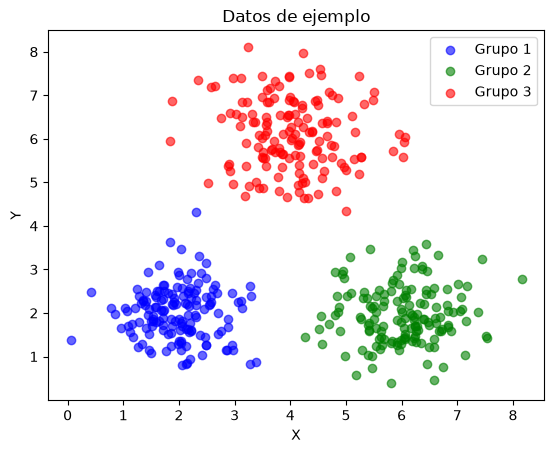

In [52]:
plt.scatter(C1[:,0],C1[:,1], color='blue', alpha=0.6)
plt.scatter(C2[:,0],C2[:,1], color='green', alpha=0.6)
plt.scatter(C3[:,0],C3[:,1], color='red', alpha=0.6)
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Datos de ejemplo')
plt.legend(['Grupo 1', 'Grupo 2', 'Grupo 3'])
plt.show()

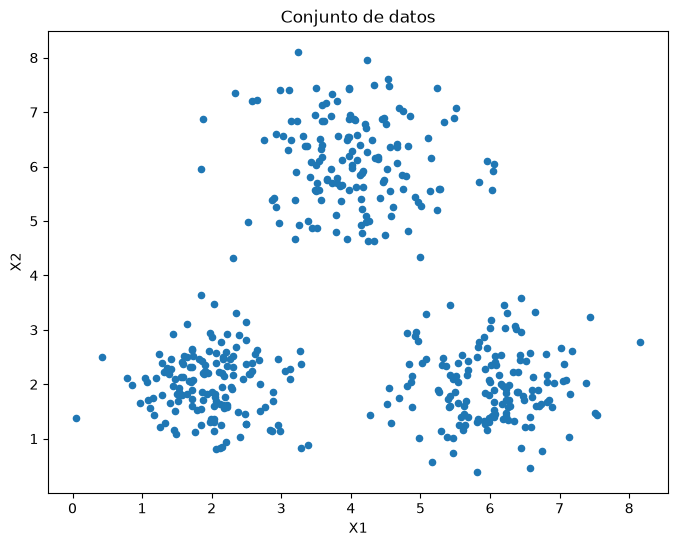

In [53]:
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=20)
plt.title("Conjunto de datos")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()


In [54]:
class KMeans:
    def __init__(self, n_clusters=3, max_iter=100, random_state=None):
        self.n_clusters=n_clusters
        self.max_iter=max_iter
        self.random_state=random_state

    def fit(self, X):
        
        X= np.asarray(X, dtype=float)
        N,D = X.shape

        rng=np.random.default_rng(self.random_state)

        centros=rng.choice(N, size=self.n_clusters, replace=False)

        self.centroides=X[centros].copy()
        
        self.historial=[]
        
        self.etiqueta=np.full(N, -1)
        
        for i in range(self.max_iter):

            centroides_viejos=self.centroides.copy()
        
            distances=((X[:,None,:]-self.centroides[None,:,:])**2).sum(axis=2)
        
            self.etiqueta=np.argmin(distances, axis=1)

            for k in range(self.n_clusters):

                xk=X[self.etiqueta==k]

                if len(xk)>0:
                    self.centroides[k]=xk.mean(axis=0)

                else:
                    j = rng.integers(N)
                    self.centroides[k] = X[j]
            self.n_iter = i + 1
            if np.allclose(self.centroides,centroides_viejos):
                break
        distances = ((X[:,None,:] -self.centroides[None,:,:])**2).sum(axis=2)
        self.etiqueta = np.argmin(distances, axis=1)
        errores = np.sum((X-self.centroides[self.etiqueta])**2)
        self.historial.append(errores)
        print(f"Numero de iteraciones:{self.n_iter}")

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        distances = ((X[:, None, :] - self.centroides[None, :, :]) ** 2).sum(axis=2)
        return np.argmin(distances, axis=1)


In [55]:
modelo=KMeans

In [56]:
modelo.fit(X)

TypeError: KMeans.fit() missing 1 required positional argument: 'X'